# **Classification of Single-Cell Yeast RNA-Seq based on Functional Signatures**

*Martina Montonati - BCG A.Y 2025/2026*

## 1. Introduction of the Problem
*Saccharomyces Cerevisiae*, widely known as *budding yeast*, is a unicellular eukaryote belonging to the fungi kingdom, and a foundational model organism in biological research. Its genome, composed of approximately 12 million base pairs, organized into 16 chromosomes and more than 6000 genes, was the first eukaryotic genome to be entirely sequenced in 1996. To survive, yeast cells respond to environmental changes by altering the expression of thousands of genes, creating a genomic expression program that is customized for each specific environment, such as a new culture medium <a href="#ref-1">[1]</a>.  

Single-cell RNA sequencing (scRNA-seq) is a powerful technology that captures these transcriptomic shifts at the resolution of individual cells, revealing cellular heterogeneity often masked in traditional bulk sequencing. Specifically, the transcriptomic data utilized in this project was generated using *yeastDrop-Seq*, a single-cell platform optimized to quantify cell-specific mRNA molecules and assess the transcriptomic features induced by different environmental conditions <a href="#ref-1">[2]</a>.  
  
While scRNA-seq provides unprecedented biological resolution, the resulting data matrix is sparse, noisy and high-dimensional. Feeding raw gene counts directly into a machine learning algorithm often leads to a phenomenon known as *curse of dimensionality*, resulting in algorithmic overfitting and poor biological interpretability. To overcome these limitations, it is advantageous to aggregate individual genes into functional pathways or Gene Ontology categories. Shifting from a noisy "gene-centric" approach, to a robust "pathway-centric" paradigm, acts as a powerful dimensionality reduction technique. 

## 2. Aim of the Project
The primary objective of this project is to develop a predictive analytical framework that bridges high-dimensional single-cell transcriptomics with functional biology. Specifically, the workflow is designed to transform raw gene expression data (read counts) into a normalized Pathway Expression Index, which will subsequently be used to train Machine Learning classification models.

To achieve this, the project focuses on two main analytical goals:

* Predictive Classification: To build and evaluate Machine Learning models capable of accurately predicting the specific environmental condition (culture medium) in which each individual yeast cell was grown, based only on its aggregated metabolic signature.

* Biological Feature Extraction: To achieve interpretability of the trained models and to identify and rank the most influential biological processes. This step aims to uncover which specific functional pathways act as the key metabolic drivers governing the cellular adaptation to different media.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
from goatools.anno.gaf_reader import GafReader
from goatools.obo_parser import GODag

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import f1_score

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import (classification_report, 
                             confusion_matrix, 
                             ConfusionMatrixDisplay,
                             precision_recall_fscore_support,
                             accuracy_score)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

<!-- # ==========================================
# STEP 1: Caricamento Dati e Preprocessing
# ==========================================
# (Esempio basato sull'estensione .mtx e sui file tsv dei metadati)
# expression_matrix = sio.mmread('GSE165686_yeastdropseq_dge.mtx.gz').toarray()
# genes = pd.read_csv('genes.tsv', sep='\t', header=None)
# metadata = pd.read_csv('metadata.tsv', sep='\t')

# Creiamo un DataFrame pandas (Celle sulle righe, Geni sulle colonne)
# df_expr = pd.DataFrame(expression_matrix.T, columns=genes[0])

# controlliamo la forma del DataFrame
# controlliamo la distribuzione delle read counts
# Applichiamo la log-transform (come suggerito dal testo) per gestire l'asimmetria delle read counts
# df_expr_log = np.log1p(df_expr) -->

# 3. Implementation

## 3.1 Data Preprocessing

### *Data Loading and Structural Alignment*
The single-cell RNA sequencing data was provided in the Matrix Market (.mtx) format, a sparse matrix format as output by Cell Ranger, that separates numerical expression counts from their corresponding text labels to optimize storage.  
The raw .mtx file contains a count matrix where rows represent genes and columns represent individual cells. The text labels for these dimensions are stored separately in the *features.tsv* and *barcodes.tsv* files. The mapping between the labels and the matrix is strictly positional: the i-th row in the expression matrix perfectly aligns with the i-th gene in the features file, and the j-th column aligns with the j-th cell barcode.  
To prepare the dataset for downstream machine learning tasks, the matrix is transposed. This transformation shifts the data into the standard (n_samples, n_features) orientation, with cells as rows (observations) and genes as columns (variables), which is natively required by standard Python data science libraries such as Pandas and Scikit-Learn.

In [2]:
# Load the expression matrix, gene features, cell barcodes, and metadata
expression_matrix = sc.read_mtx('GSE165686_yeastdropseq_dge.mtx')
features = pd.read_csv('features.tsv', sep ='\t')
barcodes = pd.read_csv('barcodes.tsv', sep ='\t')
metadata = pd.read_csv('metadata.tsv', sep ='\t')
metadata.head() 

,Unnamed: 0,sample,sc3_8_clusters,sc3_4_clusters,PC_1,PC_2,PC_3,UMAP_1,UMAP_2
0,AAAAGATTATGA,DMSO,DMSO.1,3,6.527174,-7.677352,-6.994669,2.212932,3.913240
1,AAACAAAGAGGA,DMSO,DMSO.1,1,-3.163107,-3.880306,2.174751,1.483353,-1.860849
2,AAAGCCTATGTA,DMSO,DMSO.1,1,-5.735034,-2.363518,2.823618,1.619440,-2.293614
3,AAAGTTCCTTCG,DMSO,DMSO.1,3,5.783699,-7.457446,-5.531393,2.187911,3.793437
4,AAATGACTTCAC,DMSO,DMSO.2,2,3.542129,-3.103941,-8.892211,2.094342,4.569191


In [3]:
# The raw matrix is stored as genes (rows) x cells (columns); inspect before transposing
print("Expression Matrix Shape:", expression_matrix.shape) # 4777 genes x 844 cells
print("Features Shape:", features.shape) # 4777 genes
print("Barcodes Shape:", barcodes.shape) # 844 cells
print("Metadata Shape:", metadata.shape)

Expression Matrix Shape: (4777, 844)
Features Shape: (4777, 2)
Barcodes Shape: (844, 2)
Metadata Shape: (844, 9)


In [4]:
# Transpose the expression matrix in order to have cells as rows and genes as columns
# matching the convention expected by scanpy/AnnData and by scikit-learn (samples x features)
expression_matrix = expression_matrix.T

# Assign feature names (gene symbols) and cell barcodes to the expression matrix as variable - observation names
expression_matrix.var_names = features.iloc[:,1].values
expression_matrix.obs_names = barcodes.iloc[:,1].values

print("Expression Matrix Shape (cells x genes):", expression_matrix.shape) # 844 cells x 4777 genes

Expression Matrix Shape (cells x genes): (844, 4777)


In [5]:
# Explore the Features and Barcodes data
print(features.head())
print(barcodes.head())

   Unnamed: 0        x
0           1     LSR1
1           2   RDN5-1
2           3    RUF20
3           4     TLC1
4           5  YAL001C
   Unnamed: 0             x
0           1  AAAAGATTATGA
1           2  AAACAAAGAGGA
2           3  AAAGCCTATGTA
3           4  AAAGTTCCTTCG
4           5  AAATGACTTCAC


### *Data Distribution and Transformation* 
To prepare the single-cell RNA sequencing data for downstream classification, preprocessing steps were applied and visually validated. The side-by-side comparison of the expression distributions clearly highlights the need for this approach.  
Raw single-cell counts (left panel) are inherently noisy and heavily right-skewed, characterized by extreme overdispersion. To address this, a two-step normalization strategy was implemented, mirroring the Seurat LogNormalize method. First, to account for variable sequencing depths across different cells (library size bias), the counts within each cell were scaled to a target sum of $10^4$. This ensures that a cell sequenced more deeply does not artificially appear to have a higher overall activity.  
Second, a $\log(x + 1)$ transformation was applied to stabilize the variance and compress extreme outliers. As demonstrated in the right panel, this transformation successfully mitigates the long-tail effect.

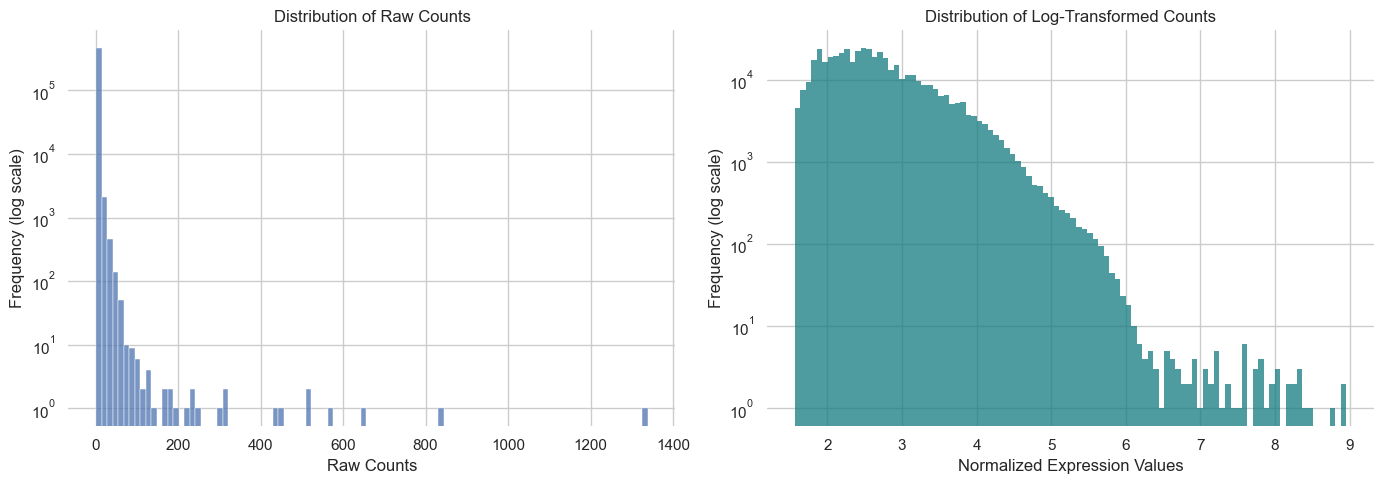

In [6]:
# Visualizing distribution of raw counts and log-transformed counts in the expression matrix

raw_counts = expression_matrix.X.data.copy()

sc.pp.normalize_total(expression_matrix, target_sum=1e4)
sc.pp.log1p(expression_matrix)
norm_log_counts = expression_matrix.X.data

figure, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(raw_counts, bins=100, ax=axes[0])
axes[0].set_title('Distribution of Raw Counts')
axes[0].set_xlabel('Raw Counts')
axes[0].set_ylabel('Frequency (log scale)')
axes[0].set_yscale('log')

sns.histplot(norm_log_counts, bins=100, ax=axes[1], color="#137B80", edgecolor="none")
axes[1].set_title('Distribution of Log-Transformed Counts')
axes[1].set_xlabel('Normalized Expression Values')
axes[1].set_ylabel('Frequency (log scale)')
axes[1].set_yscale('log')

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

In [7]:
# Transform the expression matrix to a DataFrame
expression_df = expression_matrix.to_df()

print(f'Expression DataFrame Shape: {expression_df.shape}')
expression_df.head()

Expression DataFrame Shape: (844, 4777)


,LSR1,RDN5-1,RUF20,TLC1,YAL001C,YAL002W,YAL003W,YAL005C,YAL007C,YAL008W,...,snR48,snR49,snR62,snR70,snR76,snR86,tE(UUC)E2,tL(UAG)L1,tP(UGG)H,tS(AGA)G
AAAAGATTATGA,0.000000,0.0,1.565189,1.565189,0.000000,0.0,4.288924,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACAAAGAGGA,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAAGCCTATGTA,0.000000,0.0,0.000000,0.000000,0.000000,0.0,4.774211,3.023808,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAAGTTCCTTCG,1.941125,0.0,0.000000,0.000000,1.941125,0.0,4.284952,1.941125,1.941125,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAATGACTTCAC,0.000000,0.0,0.000000,0.000000,0.000000,0.0,2.639336,0.000000,2.015163,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 3.2 Feature Engineering (Pathway Index)

The Gene Association File (GAF) file contains annotation data provided by the Gene Ontology Consortium in standardized tab-delimited text files. Each line in the file represents an association between a gene product and a GO term.  
https://geneontology.org/docs/go-annotation-file-gaf-format-2.2/

In [8]:
# Inspecting Gene Ontology Association Files (GAF) 
with open('YEAST-mod.gaf') as gaf_file:
    gaf_lines = gaf_file.readlines()
    for line in gaf_lines[:15]:  
        print(repr(line))  # Use repr to visualize special characters like tabs

'!gaf-version: 2.2\n'
'!generated-by: UniProt\n'
'!date-generated: 2026-08-04 15:09\n'
'!go-version: http://purl.obolibrary.org/obo/go/releases/2026-08-02/extensions/go-plus.ofn\n'
'SGD\tS000000001\tTFC3\tcontributes_to\tGO:0001002\tPMID:2404611\tIDA\t\tF\ttranscription factor TFIIIC subunit TFC3\tFUN24|TSV115|YAL001C\tprotein\tNCBITaxon:559292\t20130807\tSGD\t\tSGD:S000000001\n'
'SGD\tS000000001\tTFC3\tcontributes_to\tGO:0001002\tPMID:2649882\tIDA\t\tF\ttranscription factor TFIIIC subunit TFC3\tFUN24|TSV115|YAL001C\tprotein\tNCBITaxon:559292\t20130807\tSGD\t\tSGD:S000000001\n'
'SGD\tS000000001\tTFC3\tcontributes_to\tGO:0001003\tPMID:2404611\tIDA\t\tF\ttranscription factor TFIIIC subunit TFC3\tFUN24|TSV115|YAL001C\tprotein\tNCBITaxon:559292\t20130807\tSGD\t\tSGD:S000000001\n'
'SGD\tS000000001\tTFC3\tcontributes_to\tGO:0008301\tPMID:2002052\tIDA\t\tF\ttranscription factor TFIIIC subunit TFC3\tFUN24|TSV115|YAL001C\tprotein\tNCBITaxon:559292\t20130807\tSGD\t\tSGD:S000000001\n'
'SGD\tS0000

  To accurately map the single-cell transcriptomic features to their corresponding functional categories, the GO Annotation File (GAF) was parsed using the `goatools` Python library. Utilizing a dedicated and community-standardized parser ensures robust handling of the GAF structure, including proper extraction of gene aliases and synonyms. The annotations were strictly filtered for the 'Biological Process' aspect to align with the metabolic and functional scope of the project.

In [9]:
# Loading and exploring GAF file
gaf = GafReader('YEAST-mod.gaf')
ns2assc = gaf.get_ns2assc()

for namespace, associations in ns2assc.items():
    for protein_id, go_ids in sorted(associations.items())[:3]:
        print("{NS} {PROT:7} : {GOs}".format(
            NS=namespace, # (MF = Molecular Function, BP = Biological Process, CC = Cellular Component)
            PROT=protein_id,
            GOs=' '.join(sorted(go_ids))))

HMS:0:00:04.092791 142,056 annotations READ: YEAST-mod.gaf 
MF S000000001 : GO:0000995 GO:0001002 GO:0001003 GO:0003677 GO:0008301
MF S000000002 : GO:0008270 GO:0043495 GO:0051020
MF S000000003 : GO:0003746 GO:0005085 GO:0005515
BP S000000001 : GO:0006383 GO:0006384 GO:0042791 GO:0071168
BP S000000002 : GO:0006623 GO:0006886 GO:0007009 GO:0016192 GO:0032511 GO:0032889 GO:0034058
BP S000000003 : GO:0006414 GO:0006449 GO:0032232 GO:1990145
CC S000000001 : GO:0000127 GO:0005634 GO:0005654 GO:0005739
CC S000000002 : GO:0005768 GO:0005770 GO:0005795 GO:0016020 GO:0031901 GO:0033263 GO:0098588 GO:0099023
CC S000000003 : GO:0005829 GO:0005840 GO:0005853 GO:0032991


In [10]:
# Exploring the first 10 associations in the GAF file
nts = sorted(gaf.associations, key=lambda nt:nt.DB_ID)
fmtpat = '{DB_ID} {DB_Symbol:13} {GO_ID} {NS} ' 
for nt_line in nts[:10]:
    print(fmtpat.format(**nt_line._asdict()))

S000000001 TFC3          GO:0001002 MF 
S000000001 TFC3          GO:0001002 MF 
S000000001 TFC3          GO:0001003 MF 
S000000001 TFC3          GO:0008301 MF 
S000000001 TFC3          GO:0000995 MF 
S000000001 TFC3          GO:0003677 MF 
S000000001 TFC3          GO:0006383 BP 
S000000001 TFC3          GO:0006383 BP 
S000000001 TFC3          GO:0006383 BP 
S000000001 TFC3          GO:0006384 BP 


In [11]:
# Creating a dictionary mapping pathways (Biological Processes) to their associated genes

pathway_to_genes = {} # {GO_ID -> set of gene symbols/synonyms}

for assoc in gaf.associations:
    if assoc.NS == 'BP': 
        go_id = assoc.GO_ID
        gene_symbol = assoc.DB_Symbol
        
        if go_id not in pathway_to_genes:
            pathway_to_genes[go_id] = set()
            
        pathway_to_genes[go_id].add(gene_symbol)
        
        for synonym in assoc.DB_Synonym:
            pathway_to_genes[go_id].add(synonym)

print(f"{len(pathway_to_genes)} Biological Process pathways found.")

3015 Biological Process pathways found.


In [12]:
# Filtering pathways to only include those with genes actually present in the expression dataset
genes = set(expression_df.columns)
print(f"Total unique genes in the dataset: {len(genes)}")

pathway_gene_matches = {}
annotated_genes_in_dataset = set()

for go_id, pathway_genes in pathway_to_genes.items():
    matching_genes = genes.intersection(pathway_genes)
    if len(matching_genes):
        pathway_gene_matches[go_id] = matching_genes
        annotated_genes_in_dataset.update(matching_genes)

print(f"Genes successfully mapped to at least one pathway: {len(annotated_genes_in_dataset)}")
print(f"Pathways passing the filter: {len(pathway_gene_matches)}")

Total unique genes in the dataset: 4777
Genes successfully mapped to at least one pathway: 4768
Pathways passing the filter: 2814


The computation of the Pathway Expression Index was executed through a precise row-wise matrix aggregation step. For each validated Gene Ontology (GO) biological process, a specific submatrix was first extracted from the global log-normalized expression dataframe, retaining only the columns corresponding to the genes annotated to that particular pathway. Subsequently, for each individual cell (represented by the rows of the dataset), the arithmetic mean of these selected features was calculated. By executing this horizontal averaging (across the gene axis), the multidimensional gene expression profile of each cell was mathematically compressed into a single continuous numerical value per pathway, forming the final cell-specific **Pathway Expression Index**.  
This aggregation strategy serves a critical dual purpose. First, it effectively mitigates the technical noise and sparsity inherent to scRNA-seq technologies by relying on the collective signal of a functional gene set rather than vulnerable individual markers. Second, because the input matrix was previously variance-stabilized via log-transformation, the arithmetic mean remains well-balanced, preventing a single hyper-expressed gene from disproportionately dominating the pathway score. The resulting continuous index provides a stable, biologically interpretable feature space optimized for downstream machine learning classification.

In [13]:
pathway_matrix_dict = {}

for go_id, matching_genes in pathway_gene_matches.items():
    gene_list = list(matching_genes)
    subset_expr = expression_df[gene_list]
    # Computing the Functional Signature
    pathway_matrix_dict[go_id] = subset_expr.mean(axis=1)

df_pathway = pd.DataFrame(pathway_matrix_dict)
print(f'Pathways DataFrame Shape: {df_pathway.shape}')
df_pathway.head()

Pathways DataFrame Shape: (844, 2814)


,GO:0006383,GO:0006384,GO:0042791,GO:0071168,GO:0006623,GO:0006886,GO:0007009,GO:0016192,GO:0032511,GO:0032889,...,GO:1902365,GO:0051668,GO:0009247,GO:0060341,GO:0031032,GO:0006294,GO:0071027,GO:0090149,GO:0007008,GO:1990882
AAAAGATTATGA,0.447197,0.340259,0.509863,0.000000,0.338938,0.468480,1.058933,0.442906,0.309427,0.472561,...,0.0,1.565189,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
AAACAAAGAGGA,0.318738,0.388028,0.000000,0.000000,0.132217,0.142585,1.065051,0.091068,0.123954,0.521216,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
AAAGCCTATGTA,0.107993,0.131470,0.000000,0.000000,0.134391,0.366771,0.918715,0.191953,0.125992,0.341015,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
AAAGTTCCTTCG,0.404369,0.492275,0.485281,1.941125,0.086272,0.476390,0.000000,0.404705,0.485281,0.612005,...,0.0,0.000000,0.000000,0.0,0.0,0.0,2.559796,0.0,0.0,0.0
AAATGACTTCAC,0.688385,0.723280,0.377589,0.000000,0.223907,0.318672,1.378132,0.280014,0.671552,0.623218,...,0.0,0.000000,2.015163,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


To validate the robustness of the pathway-centric approach, we compared the Principal Component Analysis (PCA) of the original high-dimensional gene expression matrix with the PCA of our transformed functional pathway matrix. The spatial coordinates for the original gene-level PCA were extracted directly from the pre-computed metadata provided with the dataset, As shown in the side-by-side projection, the global topological structure and the relative positioning of the cellular states are remarkably conserved. The transition from individual genes to a reduced set of functional pathways did not collapse the biological signal; rather, it successfully retained the underlying linear variance necessary to distinguish the groups. 

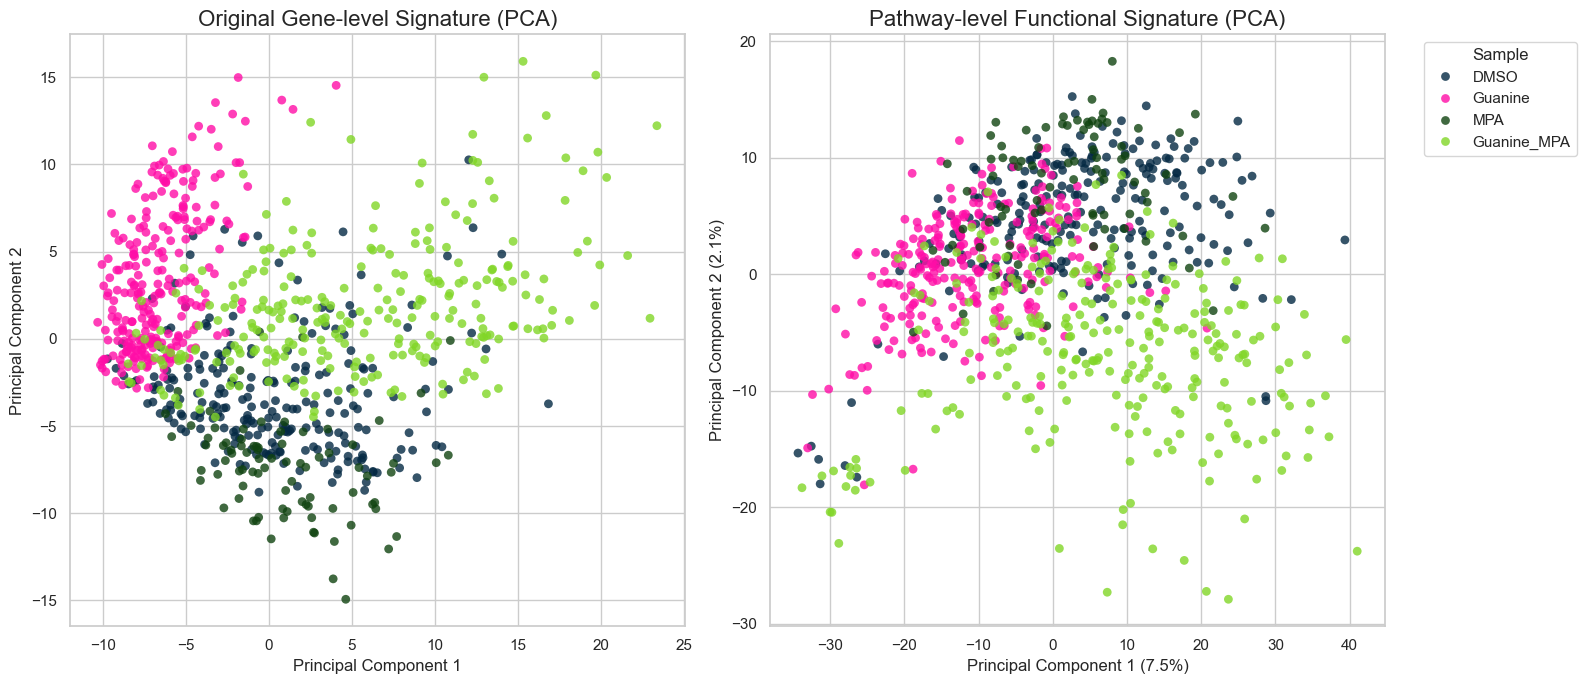

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Original Gene-level
sns.scatterplot(
    x='PC_1', 
    y='PC_2',
    hue='sample', 
    palette=["#042943", "#ff0ea7", "#104310", "#81d627"], 
    data=metadata,
    alpha=0.8,
    s=40,
    edgecolor='none',
    ax=axes[0]  
)
axes[0].set_title('Original Gene-level Signature (PCA)', fontsize=16)
axes[0].set_xlabel(f'Principal Component 1', fontsize=12)
axes[0].set_ylabel(f'Principal Component 2', fontsize=12)
axes[0].get_legend().remove()

# Pathway-level
scaler = StandardScaler()
df_pathway_scaled = scaler.fit_transform(df_pathway)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(df_pathway_scaled)

var_1 = pca.explained_variance_ratio_[0] * 100
var_2 = pca.explained_variance_ratio_[1] * 100

pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
pca_df['sample'] = metadata['sample'].values

sns.scatterplot(
    x='PC1', 
    y='PC2',
    hue='sample',
    palette=["#042943", "#ff0ea7", "#104310", "#81d627"],
    data=pca_df,
    alpha=0.8,
    s=40,            
    edgecolor='none',
    ax=axes[1]       
)
axes[1].set_title('Pathway-level Functional Signature (PCA)', fontsize=16)
axes[1].set_xlabel(f'Principal Component 1 ({var_1:.1f}%)', fontsize=12)
axes[1].set_ylabel(f'Principal Component 2 ({var_2:.1f}%)', fontsize=12)

axes[1].legend(title='Sample', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

## 3.3 Model Selection & Evaluation

Three classifier were evaluated, representing different modeling strategies:
* **Random Forest**: a non-linear ensemble algorithm, trained on raw pathway signatures
* **Logistic Regression L1**: a linear model with sparsity-inducing regularization, trained on standardized signatures
* **Linear SVM**: a margin-based linear classifier, trained on standardized signatures   

All three use `class_weight='balanced'` to compensate for class-size imbalance.  

A single reusable function,
`fit_and_evaluate`, trains a model, prints its **classification report** (Precision /
Recall / F1-score per class), plots its confusion
matrix, and returns a tidy per-class metrics table for later comparison.  

In [15]:
def fit_and_evaluate_model(model, X_train, y_train, X_test, y_test, class_names, model_name, plot_confusion=True):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=class_names))

    if plot_confusion:
        cm = confusion_matrix(y_test, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = class_names)
        disp.plot(cmap = 'Blues', xticks_rotation = 45)
        plt.title(f"Confusion Matrix - {model_name}")
        plt.tight_layout()
        plt.show()

    precision, recall, f1, support = precision_recall_fscore_support(y_test, y_pred, average=None)
    metrics_df = pd.DataFrame({ 
        'MODEL' : model_name,
        'CLASS' : class_names,
        'PRECISION' : precision,
        'RECALL' : recall,
        'F1-SCORE' : f1,
        'SUPPORT' : support
    })
    return model, y_pred, metrics_df


### *Data Transformation*

In [16]:
# Align cell - level metadata to the same row order ad the pathway matrix (df_pathway)
metadata_indexed = metadata.set_index(metadata.columns[0])
metadata_aligned = metadata_indexed.loc[df_pathway.index] 

X = df_pathway
y = metadata_aligned['sample']

print(f"Class distribution:\n{y.value_counts()}\n")


Class distribution:
sample
Guanine_MPA    268
Guanine        258
DMSO           233
MPA             85
Name: count, dtype: int64



In [17]:
# Encode the labels (from text to numbers)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
class_names = label_encoder.classes_
print("Class detected:", class_names)

# Stratified train/test split preserves the class proportions in both training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, 
    test_size=0.20, 
    random_state=RANDOM_STATE, 
    stratify=y_encoded
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")


Class detected: ['DMSO' 'Guanine' 'Guanine_MPA' 'MPA']
Training samples: 675
Test samples: 169


In [18]:
# Standardize the data for linear models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### *Random Forest*

Classification Report:
              precision    recall  f1-score   support

        DMSO       0.88      0.63      0.73        46
     Guanine       0.78      0.96      0.86        52
 Guanine_MPA       0.83      0.89      0.86        54
         MPA       1.00      0.82      0.90        17

    accuracy                           0.83       169
   macro avg       0.87      0.83      0.84       169
weighted avg       0.84      0.83      0.83       169



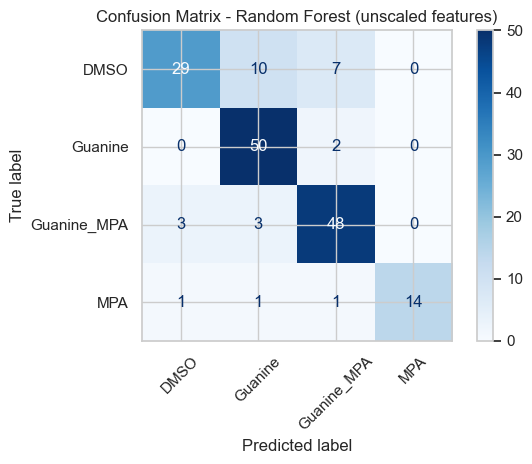

                               MODEL        CLASS  PRECISION    RECALL  \
0  Random Forest (unscaled features)         DMSO   0.878788  0.630435   
1  Random Forest (unscaled features)      Guanine   0.781250  0.961538   
2  Random Forest (unscaled features)  Guanine_MPA   0.827586  0.888889   
3  Random Forest (unscaled features)          MPA   1.000000  0.823529   

   F1-SCORE  SUPPORT  
0  0.734177       46  
1  0.862069       52  
2  0.857143       54  
3  0.903226       17  


In [19]:
rf_model = RandomForestClassifier(
    n_estimators=100, random_state=RANDOM_STATE, class_weight='balanced'
)
rf_model, y_pred_rf, metrics_rf = fit_and_evaluate_model(
    rf_model, X_train, y_train, X_test, y_test, class_names, "Random Forest (unscaled features)"
)
print(metrics_rf)

### *Logistic Regression - Lasso L1 penalty*

c:\Users\marte\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


Classification Report:
              precision    recall  f1-score   support

        DMSO       0.93      0.91      0.92        46
     Guanine       0.89      0.96      0.93        52
 Guanine_MPA       0.96      0.93      0.94        54
         MPA       0.94      0.88      0.91        17

    accuracy                           0.93       169
   macro avg       0.93      0.92      0.93       169
weighted avg       0.93      0.93      0.93       169



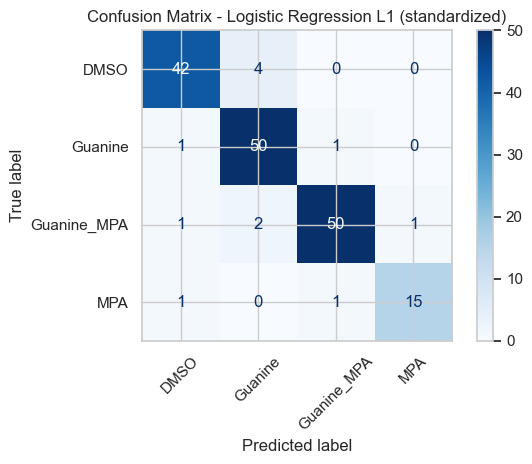

                                   MODEL        CLASS  PRECISION    RECALL  \
0  Logistic Regression L1 (standardized)         DMSO   0.933333  0.913043   
1  Logistic Regression L1 (standardized)      Guanine   0.892857  0.961538   
2  Logistic Regression L1 (standardized)  Guanine_MPA   0.961538  0.925926   
3  Logistic Regression L1 (standardized)          MPA   0.937500  0.882353   

   F1-SCORE  SUPPORT  
0  0.923077       46  
1  0.925926       52  
2  0.943396       54  
3  0.909091       17  


In [20]:
log_reg = LogisticRegression(
    penalty='l1', solver='liblinear', class_weight='balanced', random_state=RANDOM_STATE
)
log_reg, y_pred_lr, metrics_lr = fit_and_evaluate_model(
    log_reg, X_train_scaled, y_train, X_test_scaled, y_test, class_names,
    "Logistic Regression L1 (standardized)"
)
print(metrics_lr)

### *Support Vector Machine (SVM)*

Classification Report:
              precision    recall  f1-score   support

        DMSO       0.88      0.93      0.91        46
     Guanine       0.94      0.96      0.95        52
 Guanine_MPA       0.98      0.94      0.96        54
         MPA       1.00      0.88      0.94        17

    accuracy                           0.94       169
   macro avg       0.95      0.93      0.94       169
weighted avg       0.94      0.94      0.94       169



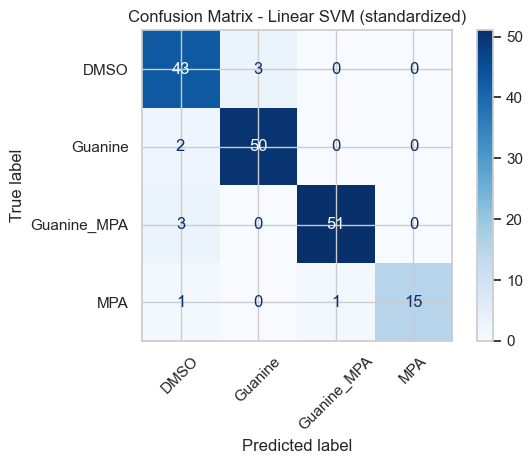

                       MODEL        CLASS  PRECISION    RECALL  F1-SCORE  \
0  Linear SVM (standardized)         DMSO   0.877551  0.934783  0.905263   
1  Linear SVM (standardized)      Guanine   0.943396  0.961538  0.952381   
2  Linear SVM (standardized)  Guanine_MPA   0.980769  0.944444  0.962264   
3  Linear SVM (standardized)          MPA   1.000000  0.882353  0.937500   

   SUPPORT  
0       46  
1       52  
2       54  
3       17  


In [21]:
svm_model = SVC(kernel='linear', class_weight='balanced', random_state=RANDOM_STATE)
svm_model, y_pred_svm, metrics_svm = fit_and_evaluate_model(
    svm_model, X_train_scaled, y_train, X_test_scaled, y_test, class_names,
    "Linear SVM (standardized)"
)
print(metrics_svm)
# Reminder: Default C value for SVM is 1.0 

### *Technical Evaluation*

In [22]:
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'Logistic Regression (L1)', 'Linear SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svm),
    ]
}).sort_values('Accuracy', ascending=False)

print("--- Model Selection: Overall Accuracy ---")
print(comparison.to_string(index=False))

--- Model Selection: Overall Accuracy ---
                   Model  Accuracy
              Linear SVM  0.940828
Logistic Regression (L1)  0.928994
           Random Forest  0.834320


Below a **class-by-class**
breakdown of Precision, Recall and F1-score across models, and an explicit demonstration
of how 
- **StandardScaler vs. raw data** and 
- **hyperparameter choice** (the SVM's regularization strength `C`)

affect the F1-score.

In [23]:
all_metrics = pd.concat([metrics_rf, metrics_lr, metrics_svm], ignore_index=True)

pivot_metrics = all_metrics.pivot(
    index='CLASS', columns='MODEL', values=['PRECISION', 'RECALL', 'F1-SCORE']
).round(3)

pivot_metrics

PRECISION                                        \
MODEL       Linear SVM (standardized) Logistic Regression L1 (standardized)   
CLASS                                                                         
DMSO                            0.878                                 0.933   
Guanine                         0.943                                 0.893   
Guanine_MPA                     0.981                                 0.962   
MPA                             1.000                                 0.938   

                                                                 RECALL  \
MODEL       Random Forest (unscaled features) Linear SVM (standardized)   
CLASS                                                                     
DMSO                                    0.879                     0.935   
Guanine                                 0.781                     0.962   
Guanine_MPA                             0.828                     0.944   
MPA                                     1.000                     0.882   

                                                   \
MODEL       Logistic Regression L1 (standardized)   
CLASS                                               
DMSO                                        0.913   
Guanine                                     0.962   
Guanine_MPA                                 0.926   
MPA                                         0.882   

                                                               F1-SCORE  \
MODEL       Random Forest (unscaled features) Linear SVM (standardized)   
CLASS                                                                     
DMSO                                    0.630                     0.905   
Guanine                                 0.962                     0.952   
Guanine_MPA                             0.889                     0.962   
MPA                                     0.824                     0.938   

                                                   \
MODEL       Logistic Regression L1 (standardized)   
CLASS                                               
DMSO                                        0.923   
Guanine                                     0.926   
Guanine_MPA                                 0.943   
MPA                                         0.909   

                                               
MODEL       Random Forest (unscaled features)  
CLASS                                          
DMSO                                    0.734  
Guanine                                 0.862  
Guanine_MPA                             0.857  
MPA                                     0.903

In [24]:
print("--- SVM Data Transformation Impact ---")
# Train the SVM on RAW data
svm_raw = SVC(kernel='linear', class_weight='balanced', random_state=42)
svm_raw.fit(X_train, y_train)
f1_raw = f1_score(y_test, svm_raw.predict(X_test), average='macro')

# Train the SVM on STANDARDIZED data 
svm_scaled = SVC(kernel='linear', class_weight='balanced', random_state=42)
svm_scaled.fit(X_train_scaled, y_train)
f1_scaled = f1_score(y_test, svm_scaled.predict(X_test_scaled), average='macro')

print(f"F1-Macro on raw data:         {f1_raw:.3f}")
print(f"F1-Macro on standardized data (Z-score): {f1_scaled:.3f}\n")


print("--- SVM Hyperparameter Tuning on standardized data ---")
# Test the regularization strength of the algorithm (the C parameter)
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}

# Create a GridSearch
grid_search = GridSearchCV(
    SVC(kernel='linear', class_weight='balanced', random_state=42), 
    param_grid, 
    cv=5, # 5-fold Cross-Validation
    scoring='f1_macro'
)

grid_search.fit(X_train_scaled, y_train)

print(f"Best option for C is: {grid_search.best_params_['C']}")
print(f"Mean F1-Macro (Cross-Validation) with this parameter: {grid_search.best_score_:.3f}")

--- SVM Data Transformation Impact ---
F1-Macro on raw data:         0.915
F1-Macro on standardized data (Z-score): 0.939

--- SVM Hyperparameter Tuning on standardized data ---
Best option for C is: 0.001
Mean F1-Macro (Cross-Validation) with this parameter: 0.944


The Macro F1-score was selected as the primary evaluation metric to account for the class imbalance, ensuring that the model's performance on the rare MPA class is weighted equally to the majority groups.  

**The Transformation Impact**  
The jump from 0.915 to 0.939 proves that SVM is geometrically sensitive. Because SVM calculates margins based on the distance between data points, unscaled raw data causes features with naturally larger numeric ranges to unfairly dominate the algorithm. Z-score standardization forces all features to the same scale, directly improving the model's ability to separate the yeast nutrient classes.  

**The Hyperparameter Impact**  
A very low C value applies strong regularization, meaning the model prefers a wider, simpler decision boundary and tolerates some misclassifications on the training set. In high-dimensional single-cell data, this prevents the SVM from overfitting to technical noise, ultimately yielding the highest cross-validated score of 0.944.

--- C effect on F1-Macro (5-fold CV on Standardized Data) ---
      C  Mean F1-Macro  Std Dev
  0.001       0.943699 0.017448
  0.010       0.942586 0.014128
  0.100       0.942586 0.014128
  1.000       0.942586 0.014128
 10.000       0.942586 0.014128
100.000       0.942586 0.014128


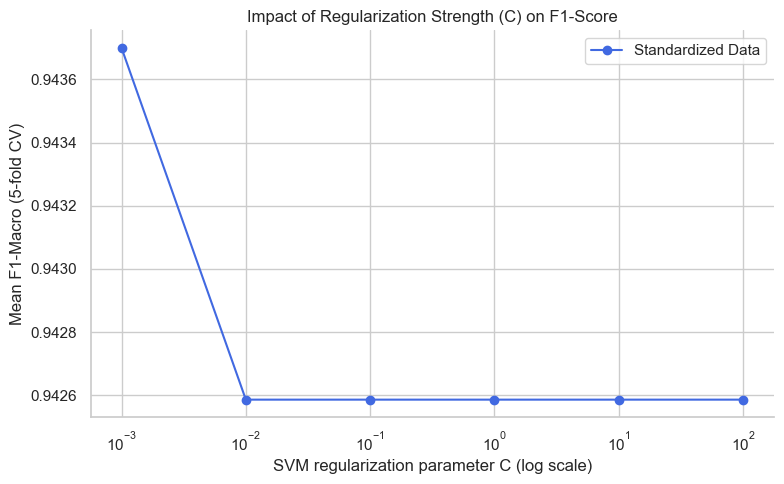

In [25]:
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results['C'] = cv_results['param_C']

summary = (
    cv_results[['C', 'mean_test_score', 'std_test_score']]
    .rename(columns={'mean_test_score': 'Mean F1-Macro', 'std_test_score': 'Std Dev'})
    .sort_values('C')
)

print("--- C effect on F1-Macro (5-fold CV on Standardized Data) ---")
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(summary['C'], summary['Mean F1-Macro'], marker='o', color='royalblue', label='Standardized Data')

ax.set_xscale('log')
ax.set_xlabel('SVM regularization parameter C (log scale)')
ax.set_ylabel('Mean F1-Macro (5-fold CV)')
ax.set_title('Impact of Regularization Strength (C) on F1-Score')
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

The table displays the results of a 5-fold Cross-Validation for the Support Vector Machine (SVM) classifier on standardized data. It evaluates how different values of the regularization parameter (C) affect the model's overall performance, which is quantified by the Mean F1-Macro score and its standard deviation.  

The line plot visualizes the relationship between the regularization strength and the classification performance. By plotting the Mean F1-Macro score against the C parameter on a logarithmic scale, the graph clearly shows that the highest F1-score is achieved at $C=0.001$. or values of $C \ge 0.01$, the score slightly drops and then plateaus. Since the $C$ parameter in an SVM is inversely proportional to the regularization strength, this plateau indicates that once a certain threshold of model complexity is reached, further relaxing the regularization (increasing $C$) does not significantly alter the linear decision boundary of the classifier.

Classification Report:
              precision    recall  f1-score   support

        DMSO       0.91      0.93      0.92        46
     Guanine       0.94      0.98      0.96        52
 Guanine_MPA       0.98      0.96      0.97        54
         MPA       1.00      0.88      0.94        17

    accuracy                           0.95       169
   macro avg       0.96      0.94      0.95       169
weighted avg       0.95      0.95      0.95       169



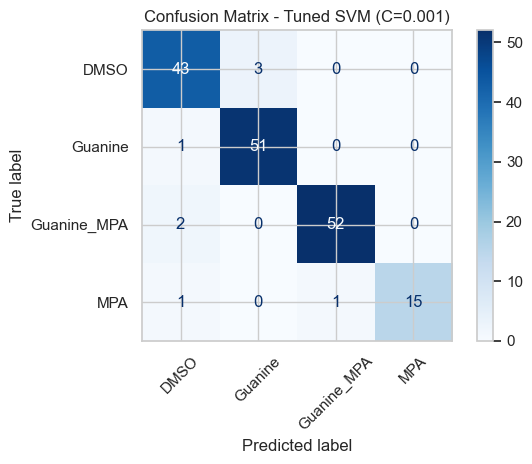

                 MODEL        CLASS  PRECISION    RECALL  F1-SCORE  SUPPORT
0  Tuned SVM (C=0.001)         DMSO   0.914894  0.934783  0.924731       46
1  Tuned SVM (C=0.001)      Guanine   0.944444  0.980769  0.962264       52
2  Tuned SVM (C=0.001)  Guanine_MPA   0.981132  0.962963  0.971963       54
3  Tuned SVM (C=0.001)          MPA   1.000000  0.882353  0.937500       17


In [26]:
# Final evaluation of the SVM tuned model
best_svm = grid_search.best_estimator_
_, y_pred_best, metrics_best = fit_and_evaluate_model(
    best_svm, 
    X_train_scaled, 
    y_train, 
    X_test_scaled, 
    y_test, 
    class_names, 
    f"Tuned SVM (C={grid_search.best_params_['C']})"
)
print(metrics_best)

## 4. Biological Interpretation


Random Forest's
`feature_importances_` tell us which pathway signatures were most useful in separating
the classes, and `goatools`'s `GODag` lets us attach a human-readable pathway name to
each Gene Ontology ID.

In [27]:
importances = rf_model.feature_importances_

feature_names = X_train.columns
df_importances = pd.DataFrame({
    'Pathway_ID': feature_names,
    'Importance': importances
})


df_importances = df_importances.sort_values(by='Importance', ascending=False)
top_20_pathways = df_importances.head(20)

print("--- Top 20 Pathway ---")
print(top_20_pathways)

--- Top 20 Pathway ---
      Pathway_ID  Importance
16    GO:0002181    0.009510
362   GO:0006412    0.008543
151   GO:0006364    0.008395
1076  GO:0000027    0.008388
1450  GO:0031120    0.007556
1126  GO:0042254    0.007529
17    GO:0006457    0.007286
1023  GO:0000470    0.006293
1068  GO:0000492    0.006094
1778  GO:0042744    0.005755
579   GO:0000028    0.005719
161   GO:0000462    0.005707
766   GO:0034504    0.005703
1292  GO:0000054    0.005623
26    GO:0070482    0.005589
430   GO:0050821    0.005353
2117  GO:0006885    0.004996
799   GO:0043248    0.004968
2547  GO:0006543    0.004916
124   GO:0042273    0.004583


go-basic.obo: fmt(1.2) rel(2026-07-26) 41,378 Terms
      Pathway_ID                                       Pathway_Name  \
16    GO:0002181                            cytoplasmic translation   
362   GO:0006412                                        translation   
151   GO:0006364                                    rRNA processing   
1076  GO:0000027                   ribosomal large subunit assembly   
1450  GO:0031120                      snRNA pseudouridine synthesis   
1126  GO:0042254                                ribosome biogenesis   
17    GO:0006457                                    protein folding   
1023  GO:0000470                             maturation of LSU-rRNA   
1068  GO:0000492                            box C/D snoRNP assembly   
1778  GO:0042744                hydrogen peroxide catabolic process   
579   GO:0000028                   ribosomal small subunit assembly   
161   GO:0000462  maturation of SSU-rRNA from tricistronic rRNA ...   
766   GO:0034504         

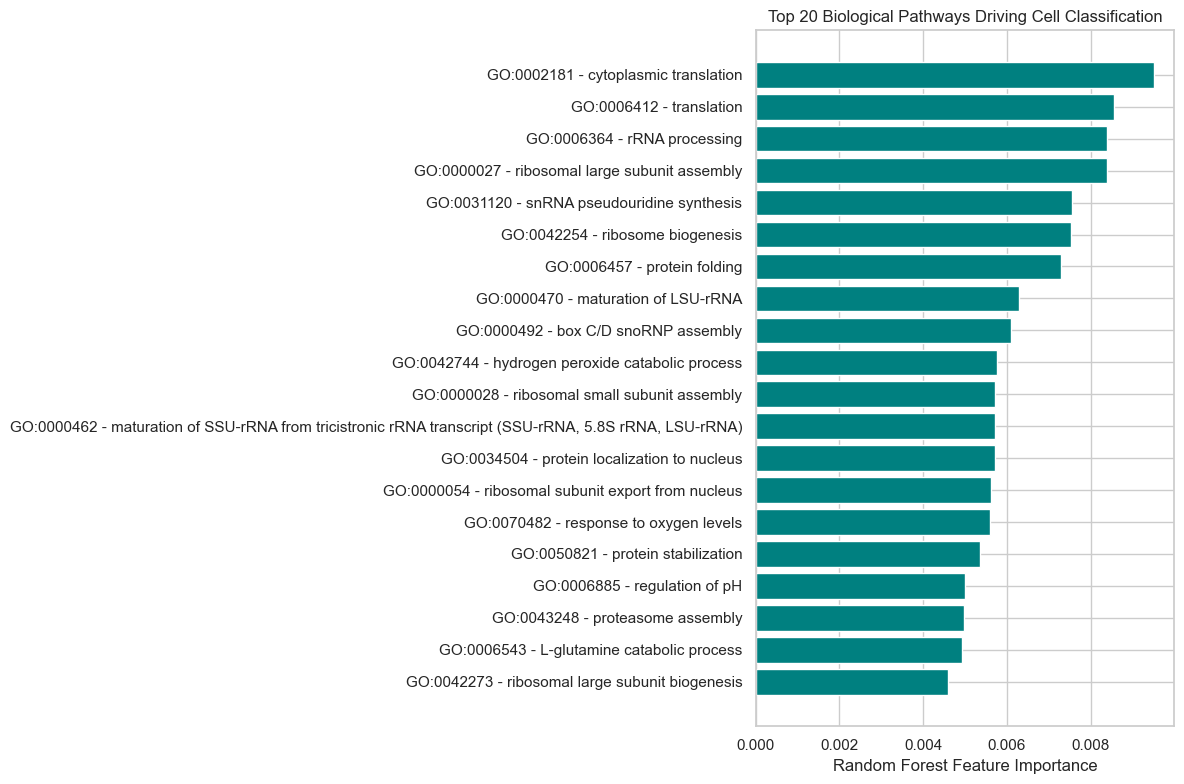

In [28]:
go_dag = GODag("go-basic.obo")

def get_go_name(go_id):
    if go_id in go_dag:
        return go_dag[go_id].name
    return "Name not found"

top_20 = top_20_pathways.copy()
top_20['Pathway_Name'] = top_20['Pathway_ID'].apply(get_go_name)
top_20['Label'] = top_20['Pathway_ID'] + " - " + top_20['Pathway_Name']

print(top_20[['Pathway_ID', 'Pathway_Name', 'Importance']])

plt.figure(figsize=(12, 8))
plt.barh(top_20['Label'][::-1], top_20['Importance'][::-1], color='teal')
plt.xlabel("Random Forest Feature Importance")
plt.title("Top 20 Biological Pathways Driving Cell Classification")
plt.tight_layout()
plt.show()

## 5. Discussion & Conclusion

The evaluation of the three modeling strategies clearly demonstrates the critical role of data standardization in classifying high-dimensional scRNA-seq data. The non-linear Random Forest baseline, trained on raw pathway signatures, achieved an 83% accuracy (Macro F1: 0.84) and perfectly identified the minority MPA class, but struggled severely with the DMSO control group (Recall: 0.63), misclassifying over a third of untreated cells as treated. Shifting to standardized features resolved this issue: the Logistic Regression model with sparsity-inducing L1 regularization reached over 93% accuracy, effectively isolating core biological pathways and boosting DMSO recall to 0.91. Finally, the baseline Linear SVM (C=1.0) established the most robust geometric separation, outperforming both models with 94% accuracy. By maintaining perfect precision on the MPA class and further stabilizing the DMSO group (Recall: 0.93) with only few misclassifications, the SVM demonstrated that properly scaled, margin-based linear hyperplanes provide the most effective classification of these cellular states, setting a remarkably high performance floor even before fine-tuning the regularization strength.  
Following the hyperparameter tuning phase, the final optimized Support Vector Machine (C=0.001) achieved the highest overall performance, reaching an accuracy of 95% (Macro F1: 0.95). The strong regularization parameter successfully reduced overfitting to high-dimensional noise, resulting in a clean separation of the cellular states. The model maintained perfect precision (1.00) on the minority MPA class and achieved near-perfect F1-scores for the complex Guanine (0.96) and Guanine_MPA (0.97) treatments. The confusion matrix confirms a highly robust diagonal, with the DMSO control group effectively stabilized (43 out of 46 cells correctly classified). The rare misclassifications are minor and well-contained, demonstrating that the combination of Z-score standardization and aggressive regularization yields an optimal linear decision boundary for this scRNA-seq dataset. This proves just how extreme and unique the MPA transcriptomic signature is.

Feature importance analysis reveals that pathways governing protein synthesis ('cytoplasmic translation') and ribosome construction ('ribosomal large subunit assembly') are the model's primary predictors, a finding that perfectly mirrors the known biological mechanism of Mycophenolic acid (MPA). MPA inhibits the IMPDH enzyme, causing a severe depletion of intracellular GTP. To survive this metabolic starvation, cells trigger an Environmental Stress Response (ESR), abruptly halting energy-intensive processes like ribosome biogenesis and translation <a href="#ref-1">[3]</a>. As Taymaz-Nikerel et al.<a href="#ref-1">[4]</a> demonstrated, yeast cells maximize resource efficiency during restricted growth by massively reprogramming their transcriptome to selectively downregulate protein biosynthesis. At the molecular level, Jurkiewicz et al. <a href="#ref-1">[5]</a> proved that this MPA-induced GTP depletion directly inhibits RNA Polymerase III, rapidly terminating tRNA gene transcription and effectively breaking the cell's fundamental translational machinery. The machine learning models independently captured this physiological adaptation by utilizing the sharp transcriptomic suppression of these specific pathways as the defining signature of the MPA-induced stress state. Furthermore, this biological framework explains how the model accurately identifies Guanine-rescued cells: by utilizing the nucleotide salvage pathway, these cells bypass the IMPDH blockade, restore their GTP pools, and upregulate translational pathways back to healthy control levels—a physiological recovery clearly detected by the classifier.  

**Future Perspectives**  
Although the pathway-centric model achieved exceptional results, the limited sample size of this dataset must be critically acknowledged. The test set comprises only 169 cells in total, with the critical MPA class represented by a mere 17 cells. Consequently, the risk of algorithmic overfitting remains a factor, despite the aggressive regularization applied. Future work must validate this approach on larger, independent scRNA-seq cohorts to confirm its statistical robustness and generalizability.

# References
<p id="ref-1">[1] Gasch, A P et al., <i>“Genomic expression programs in the response of yeast cells to environmental changes.”</i>, Molecular Biology of the Cell, vol. 11,12 (2000), <a href="https://doi.org/10.1091/mbc.11.12.4241" target="_blank">doi:10.1091/mbc.11.12.4241</a></p>  
<p id="ref-1">[2] Urbonaite, G., Lee, J.T.H., Liu, P. et al., <i>“A yeast-optimized single-cell transcriptomics platform elucidates how mycophenolic acid and guanine alter global mRNA levels.”</i>, Commun Biol 4, 822 (2021) <a href="https://doi.org/10.1038/s42003-021-02320-w" target="_blank">https://doi.org/10.1038/s42003-021-02320-w</a></p> 
<p id="ref-1">[3] Liu, P., Sarnoski, E.A., Olmez, T.T. et al., <i>“Characterization of the impact of GMP/GDP synthesis inhibition on replicative lifespan extension in yeast.”</i>, Curr Genet 66, 813–822 (2020), <a href="https://doi.org/10.1007/s00294-020-01068-w" target="_blank">https://doi.org/10.1007/s00294-020-01068-w</a></p> 
<p id="ref-1">[4] Taymaz-Nikerel, Hilal et al., <i>“Genome-Wide Transcriptional Response of Saccharomyces cerevisiae to Stress-Induced Perturbations.”</i>, Frontiers in bioengineering and biotechnology, vol. 4 17. 18 Feb. 2016, <a href="doi:10.3389/fbioe.2016.00017" target="_blank">doi:10.3389/fbioe.2016.00017</a></p> 
<p id="ref-1">[5] Jurkiewicz, Aneta et al., <i>“Inhibition of tRNA Gene Transcription by the Immunosuppressant Mycophenolic Acid.”</i>, Molecular and cellular biology vol. 40,1 e00294-19. 11 Dec. 2019, <a href="doi:10.1128/MCB.00294-19">doi:10.1128/MCB.00294-19</a></p> 
